# Imports

In [1]:
# General imports
import os
import pickle

from glob import glob
from tqdm import tqdm

import numpy as np
import pandas as pd
tqdm.pandas()

# Visualization
import seaborn as sns
from matplotlib import pyplot as plt
import matplotlib.lines as mlines
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import toml
from scipy import stats
from typing import Dict

# For parameter parsing
from SCI_py.software_comparison.parameters.diann import extract_params as extract_params_diann
from SCI_py.software_comparison.parameters.spectronaut import read_spectronaut_settings as extract_params_spectronaut
from SCI_py.software_comparison.parameters.msaid import extract_params as  extract_params_msaid
from SCI_py.software_comparison.parameters.alphadia import extract_params as  extract_params_alphadia
from SCI_py.software_comparison.parameters.peaks import extract_params as extract_params_peaks
from SCI_py.software_comparison.parameters.fragger import extract_params as extract_params_fragpipe

# Data reading
from SCI_py.software_comparison.read_quantqc import (
    read_data_msaid,
    read_data_diann,
    read_data_alphadia,
    read_data_spectronaut,
    read_data_peaks,
    read_data_fragpipe_diannquant
)


from SCI_py.software_comparison.constants import search_settings_names

from SCI_py.metadata.parse import FILENAME_CONVERTERS

In [2]:
from SCI_py.software_comparison.parse.parse_settings import ParseSettingsBuilder

# Paths

In [3]:
root_QCQuant = '/public/conode53/sam/SCI_paper/QC_Quant'
root_raw = '/public/conode53/sam/SCI'

METADATA_PATH = '/home/sam/SCI/SCI/Data/metadata/metadata.parquet'

LABNAME_TO_RAW = {
    'DTU_Astral_1': os.path.join(root_raw, 'Erwin', 'raw', 'mixture'),
    'LSMBO_Astral_1': os.path.join(root_raw, 'Jeewan', 'raw', 'mixture'),
    'KI_Astral_1': os.path.join(root_raw, 'KI_Akos', 'raw', 'mixture'),
    'Wyss_Astral_1': os.path.join(root_raw, 'Bogdan', 'raw', 'mixture'),
    'IMP_Astral_1': os.path.join(root_raw, 'Karl_plate_5', 'raw', 'mixture'),
    'KI_Astral_2': os.path.join(root_raw, 'KI_Akos_11', 'raw', 'mixture'),
    'IMP_timsTOF_1':  os.path.join(root_raw, 'Karl_plate_6', 'raw', 'mixture'),
    'Broad_timsTOF_1': os.path.join(root_raw, 'Claudia', 'raw', 'mixture'),
    'BYU_timsTOF_1': os.path.join(root_raw, 'Kelly', 'raw', 'mixture')
}
VERBOSE = False

# Load data

In [4]:
metadata = pd.read_parquet(METADATA_PATH)

In [5]:
tables = []

for result_folder in tqdm(
    glob(
        os.path.join(
            root_QCQuant, # Root with the results for the mixture samples
            '*', # Lab (plate_id)
            '*', # Search engine
            '*', # Settings configuration (number)
        )
    )
):
    result_folder_split = result_folder.split('/')
    lab, search_engine, settings = result_folder_split[-3], result_folder_split[-2], result_folder_split[-1]
    if settings not in search_settings_names[search_engine].keys():
        if VERBOSE:
            print('Setting number `{}` was not configured for search engine `{}`'.format(settings, search_engine))
        continue
    
    metadata_lab = metadata[metadata['plate_id']==lab]
    converter = FILENAME_CONVERTERS[lab]
    comment = search_settings_names[search_engine][settings]

    # Parse inputs
    if search_engine=='AlphaDIA':
        report = read_data_alphadia(
            filename=os.path.join(result_folder, 'precursors.parquet'),
            converter=converter,
            metadata=metadata_lab.copy()
        )
        user_input = extract_params_alphadia(
            os.path.join(result_folder, 'log.txt')
        )

    elif search_engine=='Chimerys':
        report = read_data_msaid(
            foldername=result_folder,
            converter=converter,
            metadata=metadata_lab.copy(),
            q_value_column='GLOBAL_Q_VALUE',
            q_value_value=.01,
            verbose=VERBOSE
        )
        user_input = extract_params_msaid(
            os.path.join(
                result_folder,
                'experiment_details.csv'
            )
        )
        search_engine = 'MSAID'

    elif search_engine == 'DIANN':
        report = read_data_diann(
            filename=os.path.join(result_folder, 'report.parquet'),
            converter=converter,
            metadata=metadata_lab.copy()
        )
        report = report[
            (report['Global.Q.Value'] < 0.01) &
            (report['Decoy'] == 0)
        ]
        report['Precursor.Quantity'] = report['Precursor.Normalised']
        user_input = extract_params_diann(
            os.path.join(result_folder, 'report.log.txt')
        )
        search_engine = 'DIA-NN'

    elif search_engine =='FragPipe':
        report = read_data_fragpipe_diannquant(
            foldername=result_folder,
            converter=converter,
            metadata=metadata.copy()
        )
        report = report[
            (report['Global.Q.Value'] < 0.01) &
            (report['Decoy'] == 0)
        ]
        report['Precursor.Quantity'] = report['Precursor.Normalised']
        with open(
            os.path.join(
                result_folder,
                'fragpipe.workflow'
            ),
            'rb'
        ) as f:
            user_input = extract_params_fragpipe(f)
        search_engine = 'FragPipe (DIA-NN quant)'

    elif search_engine == 'PEAKS':
        report = read_data_peaks(
            filename=os.path.join(result_folder, 'lfq.features.csv'),
            converter=converter,
            path_to_raw=LABNAME_TO_RAW[lab],
            metadata=metadata_lab.copy()
        )
        user_input = extract_params_peaks(os.path.join(result_folder, 'parameters.txt'))

    elif search_engine == 'Spectronaut':
        report = read_data_spectronaut(
            foldername=result_folder,
            converter=converter,
            metadata=metadata_lab.copy()
        )
        params_path = list(glob(os.path.join(
                result_folder,
                '*BGS Factory Settings.txt'
            )
        ))
        if len(params_path) != 1:
            raise Exception(f'Multiple parameter files: {params_path}')

        user_input = extract_params_spectronaut(params_path[0])
    
    else:
        continue

    # Append to tables
    tables.append(
        {
            'report': report,
            'user_input': user_input,
            'comment': comment,
            'input_format': search_engine,
            'lab_name': lab
        }
    )

100%|██████████| 184/184 [07:53<00:00,  2.57s/it]


In [6]:
# Also add those no
new_tables = []
for table in tables:
    if table['input_format'] in ['PEAKS', 'MSAID', 'Spectronaut']:
        if 'TIC-norm' in table['comment']:
            continue

        report = table['report'].copy()
        
        if table['input_format'] == 'PEAKS':
            norm_cols = [c for c in table['report'].columns if c.endswith(" Normalized Area")]
            report[norm_cols] = report[norm_cols] / report[norm_cols].sum()
        elif table['input_format'] == 'MSAID':
            tic_map = report.groupby('SAMPLE_NAME')['QUANTIFICATION'].sum().to_dict()
            report['QUANTIFICATION'] = report.apply(lambda x: x['QUANTIFICATION'] / tic_map[x['SAMPLE_NAME']], axis=1)
        elif table['input_format'] == 'Spectronaut' and table['comment'] == 'The real method-evaluation':
            print('passed')
            tic_map = report.groupby('R.FileName')['FG.Quantity'].sum().to_dict()
            report['FG.Quantity'] = report.apply(
                lambda x: x['FG.Quantity'] / tic_map[x['R.FileName']],
                axis=1
            )
        else:
            continue
            
    
        new_table = table.copy()
        new_table['report'] = report
        new_table['comment'] = table['comment'] + ' TIC-norm'
        new_tables.append(new_table)

passed


In [7]:
from SCI_py.software_comparison.parse.to_proteobench import parse_tables_to_proteobench
from SCI_py.constants.maps import LAB_NAME_MAPPING

In [8]:
datapoints, intermediates = parse_tables_to_proteobench(
    tables=tables + new_tables,
    lab_name_mapping=LAB_NAME_MAPPING,
    default_cutoff_min_prec=3
)

100%|██████████| 152/152 [15:33<00:00,  6.14s/it]


# Show performance

In [12]:
FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2'

## Across settings

In [9]:
from SCI_py.constants.plotting import LAB_COLORS, CONDITION_ORDER, LAB_ORDER, CONDITION_COLORS

In [10]:
import warnings
from SCI_py.plot.utilities import _save

def plot_benchmark_scatter(
    df:            pd.DataFrame,
    color_column:  str          = 'lab',
    color_map:     dict | None  = None,
    shape_column:  str | None   = None,
    symbol_map:    dict | None  = None,
    tool_filter:   str | None   = None,
    metric:        str          = 'mean',
    size:          int          = 70,
    title:         str | None   = None,
    save_dir:      str | None   = None,
    filename:      str          = 'benchmark_scatter.png',
    show:          bool         = True,
) -> None:
    """
    Scatter plot of precursor count vs absolute epsilon.

    Parameters
    ----------
    df:
        Long-format DataFrame with columns ``software_name``, ``nr_prec``,
        ``mean_abs_epsilon`` or ``median_abs_epsilon``, ``comments``,
        and ``color_column``.
    color_column:
        Column to use for point colors.
    color_map:
        Dict mapping ``color_column`` values to colors.
        Falls back to matplotlib color cycle if ``None``.
    shape_column:
        Column to use for point markers. ``None`` uses circles for all.
        Pass ``'comment_type'`` to split on comment suffix.
        Requires ``tool_filter`` to be set — separate legends are only
        supported for single-tool plots.
    symbol_map:
        Dict mapping ``shape_column`` values to matplotlib markers.
        Falls back to a default cycle if ``None``.
    tool_filter:
        If provided, filter to a single tool (``software_name``).
    metric:
        ``'mean'`` or ``'median'``.
    size:
        Marker size.
    title:
        Figure title. Auto-generated if ``None``.
    save_dir:
        Directory to save figures. ``None`` disables saving.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.
    """
    if shape_column is not None and tool_filter is None:
        n_colors = df[color_column].nunique()
        n_shapes = df[shape_column].nunique() if shape_column else 0
        if n_colors * n_shapes > 20:
            warnings.warn(
                f"Large number of color × shape combinations ({n_colors} × {n_shapes}). "
                "The legend may be unreadable. Consider using tool_filter to subset the data."
            )

    x_col = f'{metric}_abs_epsilon'
    if x_col not in df.columns:
        raise ValueError(f"Column '{x_col}' not found. Use metric='mean' or metric='median'.")

    df = df.copy()

    if tool_filter is not None:
        df = df[df['software_name'] == tool_filter]
        if df.empty:
            raise ValueError(f"No rows found for tool_filter='{tool_filter}'.")

    # parse comment_type if needed
    if shape_column == 'comment_type' and 'comment_type' not in df.columns:
        df['comment_type'] = df['comments'].apply(lambda x: x.split('||')[-1])

    # ── color mapping ─────────────────────────────────────────────────────────
    if color_map is None:
        categories = df[color_column].unique()
        cycle      = plt.rcParams['axes.prop_cycle'].by_key()['color']
        color_map  = {cat: cycle[i % len(cycle)] for i, cat in enumerate(categories)}

    # ── symbol mapping ────────────────────────────────────────────────────────
    _default_markers = ['o', 's', 'D', '^', 'v', 'P', 'X', '*', 'h']
    if shape_column is not None and symbol_map is None:
        unique_shapes = df[shape_column].unique()
        symbol_map    = {val: _default_markers[i % len(_default_markers)]
                         for i, val in enumerate(unique_shapes)}

    fig, ax = plt.subplots(figsize=(8, 5))

    # ── plot points ───────────────────────────────────────────────────────────
    for group in df[color_column].unique():
        sub   = df[df[color_column] == group]
        color = color_map.get(group, 'black')

        if shape_column is not None:
            for shape_val, sub_shape in sub.groupby(shape_column):
                ax.scatter(
                    sub_shape[x_col],
                    sub_shape['nr_prec'],
                    c      = color,
                    marker = symbol_map.get(shape_val, 'o'),
                    s      = size,
                    alpha  = 0.8,
                )
        else:
            ax.scatter(
                sub[x_col],
                sub['nr_prec'],
                c      = color,
                marker = 'o',
                s      = size,
                alpha  = 0.8,
                label  = group,
            )

    # ── legends ───────────────────────────────────────────────────────────────
    if shape_column is not None:
        # color legend
        color_handles = [
            plt.scatter([], [], c=color_map.get(g, 'black'), s=size, alpha=0.8, label=g)
            for g in df[color_column].unique()
        ]
        color_legend = ax.legend(
            handles        = color_handles,
            title          = color_column,
            bbox_to_anchor = (1.02, 1),
            loc            = 'upper left',
            borderaxespad  = 0,
            fontsize       = 8,
        )
        ax.add_artist(color_legend)

        # shape legend
        shape_handles = [
            plt.scatter([], [], c='black', marker=symbol_map.get(s, 'o'),
                        s=size, alpha=0.8, label=s)
            for s in df[shape_column].unique()
        ]
        ax.legend(
            handles        = shape_handles,
            title          = shape_column,
            bbox_to_anchor = (1.02, 0.4),
            loc            = 'upper left',
            borderaxespad  = 0,
            fontsize       = 8,
        )
    else:
        ax.legend(
            title          = color_column,
            bbox_to_anchor = (1.02, 1),
            loc            = 'upper left',
            borderaxespad  = 0,
            fontsize       = 8,
        )

    ax.set(
        xlabel = f'{metric.capitalize()} absolute ε',
        ylabel = 'Number of precursors',
        title  = title or (tool_filter or 'All tools'),
    )
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, color='lightgrey', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, filename))

    plt.show() if show else plt.close(fig)

In [11]:
# single tool — equivalent to old plot_individual_tool
from SCI_py.constants.plotting import SOFTWARE_COLORS

FIGURE_PATH = '/home/sam/SCI/SCI/Figures/Figure_2'

# all tools
plot_benchmark_scatter(
    df           = datapoints,
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    shape_column = 'lab',
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_all.png',
    show         = False,
)

/tmp/ipykernel_2245312/3398204430.py:59: UserWarning: Large number of color × shape combinations (6 × 9). The legend may be unreadable. Consider using tool_filter to subset the data.
  warnings.warn(


In [13]:
# single tool — equivalent to old plot_individual_tool

for software in datapoints['software_name'].unique():
    plot_benchmark_scatter(
        df           = datapoints,
        tool_filter  = software,
        color_column = 'lab',
        color_map    = LAB_COLORS,
        shape_column = 'comment_type',
        save_dir     = os.path.join(FIGURE_PATH, 'overview'),
        filename     = f'{software}_scatter.png',
        show         = False,
    )

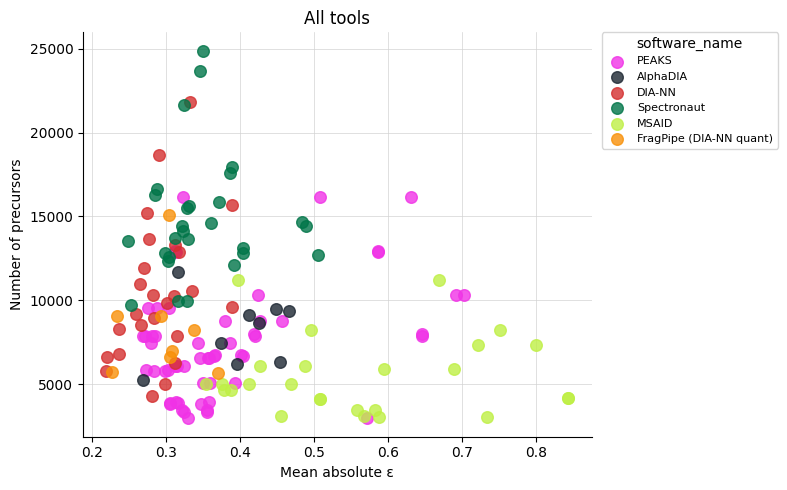

In [17]:
plot_benchmark_scatter(
    df = datapoints,
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    save_dir     = False,
    show         = True,
)

## Across software tools

In [18]:
recommended_settings_1 = {
    'AlphaDIA': 'Default',
    'CHIMERYS': '5.0.0 MS2(Area) TIC-norm',
    'MSAID': '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN': 'Library-free (recommended settings)',
    'MSFragger': 'standard',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS': 'Recommended TIC-norm',
    'Spectronaut': 'Library' 
}

recommended_settings_mbr = {
    'AlphaDIA': 'Default',
    'CHIMERYS': '5.0.0 MS2(Area) TIC-norm',
    'MSAID': '5.0.0 MS2(Area) TIC-norm',
    'DIA-NN': 'MBR',
    'MSFragger': 'standard',
    'FragPipe (DIA-NN quant)': 'standard',
    'PEAKS': 'MBR TIC-norm',
    'Spectronaut': 'Library' 
}

In [19]:
dtps_Astral = datapoints[
    (datapoints['lab'].apply(lambda x: 'Astral' in x))
]
dtps_timsTOF = datapoints[
    (datapoints['lab'].apply(lambda x: 'timsTOF' in x))
]

### Astral

In [20]:
plot_benchmark_scatter(
    df           = dtps_Astral,
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    shape_column = 'lab',
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_Astral_all.png',
    show         = False,
)

/tmp/ipykernel_2245312/3398204430.py:59: UserWarning: Large number of color × shape combinations (6 × 6). The legend may be unreadable. Consider using tool_filter to subset the data.
  warnings.warn(


Best setting:

In [23]:
plot_benchmark_scatter(
    df = dtps_Astral[
        dtps_Astral.apply(
            lambda x: x['comments']==recommended_settings_1[x['search_engine']],
            axis=1
        )],
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_astral_recommendedsetting',
    show         = False,
)

MBR:

In [24]:
plot_benchmark_scatter(
    df = dtps_Astral[
        dtps_Astral.apply(
            lambda x: x['comments']==recommended_settings_mbr[x['search_engine']],
            axis=1
        )],
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_astral_MBR',
    show         = False,
)

### timsTOF

In [25]:
plot_benchmark_scatter(
    df           = dtps_timsTOF,
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    shape_column = 'lab',
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_timsTOF_all.png',
    show         = False,
)

Best setting:

In [26]:
plot_benchmark_scatter(
    df = dtps_timsTOF[
        dtps_timsTOF.apply(
            lambda x: x['comments']==recommended_settings_1[x['search_engine']],
            axis=1
        )],
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_timsTOF_recommendedsetting',
    show         = False,
)

MBR:

In [27]:
plot_benchmark_scatter(
    df = dtps_timsTOF[
        dtps_timsTOF.apply(
            lambda x: x['comments']==recommended_settings_mbr[x['search_engine']],
            axis=1
        )],
    color_column = 'software_name',
    color_map    = SOFTWARE_COLORS,
    save_dir     = os.path.join(FIGURE_PATH, 'overview'),
    filename     = 'benchmark_scatter_timsTOF_MBR',
    show         = False,
)

# Save

Save intermediate and datapoints

In [28]:
DATA_OUT = '/home/sam/SCI/SCI/Data/ProteoBench'
with open(os.path.join(DATA_OUT, 'datapoints.pkl'), 'wb') as f:
    pickle.dump(datapoints, f)

with open(os.path.join(DATA_OUT, 'intermediates.pkl'), 'wb') as f:
    pickle.dump(intermediates, f)

In [31]:
intermediates = pd.concat(intermediates, ignore_index=True)

In [32]:
selected_intermediates = intermediates[
    (intermediates.apply(
        lambda x: x['comments']==recommended_settings_1[x['search_engine']],
        axis=1
    ))
]

selected_intermediates_mbr = intermediates[
    (intermediates.apply(
        lambda x: x['comments']==recommended_settings_mbr[x['search_engine']],
        axis=1
    ))
]

## KDEs

In [33]:
def plot_species_distributions(
    intermediates:    pd.DataFrame,
    species_config:   dict,
    color_map:        dict | None  = None,
    normalize_kde:    bool         = False,
    xlim_per_species: dict | None  = None,
    save_dir:         str | None   = None,
    filename:         str          = 'species_distributions.png',
    show:             bool         = True,
) -> None:
    """
    KDE distributions of log2 fold changes per lab and species.

    Parameters
    ----------
    intermediates:
        Long-format DataFrame with columns ``lab``, ``species``,
        ``search_engine``, ``comments``, ``log2_A_vs_B``.
    species_config:
        Dict mapping species → ``{'A_vs_B': float, 'color': str}``.
    color_map:
        Dict mapping ``search_engine`` values to colors.
        Falls back to matplotlib color cycle if ``None``.
    normalize_kde:
        If ``True``, normalise KDE to integrate to 1.
        If ``False``, scale by number of observations.
    xlim_per_species:
        Dict mapping species → ``[xmin, xmax]``.
        ``None`` uses data-driven limits.
    save_dir:
        Directory to save figures. ``None`` disables saving.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.
    """
    from scipy import stats

    lab_list      = sorted(intermediates['lab'].unique())
    species_list  = sorted(intermediates['species'].unique())
    software_list = sorted(intermediates['search_engine'].unique())

    # ── color mapping ─────────────────────────────────────────────────────────
    if color_map is None:
        cycle     = plt.rcParams['axes.prop_cycle'].by_key()['color']
        color_map = {s: cycle[i % len(cycle)] for i, s in enumerate(software_list)}

    n_labs    = len(lab_list)
    n_species = len(species_list)

    fig, axes = plt.subplots(
        n_labs, n_species,
        figsize           = (4 * n_species, 3 * n_labs),
        constrained_layout = True,
        sharey             = 'row',
    )

    # ensure 2D array
    if n_labs == 1:
        axes = axes[np.newaxis, :]
    if n_species == 1:
        axes = axes[:, np.newaxis]

    legend_handles = {}

    for row_idx, lab in enumerate(lab_list):
        for col_idx, species in enumerate(species_list):
            ax = axes[row_idx, col_idx]

            subset = intermediates[
                (intermediates['lab']     == lab) &
                (intermediates['species'] == species)
            ]

            for software in software_list:
                sw_data = subset[subset['search_engine'] == software]
                values  = sw_data['log2_A_vs_B'].dropna().values
                if len(values) < 2:
                    continue

                color  = color_map.get(software, 'black')
                kde    = stats.gaussian_kde(values)
                x_grid = np.linspace(values.min() - 1, values.max() + 1, 300)
                y_kde  = kde(x_grid)
                if not normalize_kde:
                    y_kde = y_kde * len(values)

                line, = ax.plot(x_grid, y_kde, color=color, linewidth=1.5)
                if software not in legend_handles:
                    legend_handles[software] = line

            # expected ratio line
            expected_log2 = np.log2(species_config[species]['A_vs_B'])
            ax.axvline(
                expected_log2,
                color     = species_config[species]['color'],
                linestyle = '--',
                linewidth = 1.2,
                label     = 'Expected' if row_idx == 0 else None,
            )

            # xlim
            if xlim_per_species and species in xlim_per_species:
                ax.set_xlim(xlim_per_species[species])

            if row_idx == 0:
                ax.set_title(species, fontsize=10, fontweight='bold')
            if col_idx == 0:
                ax.set_ylabel(lab, fontsize=8)
            if row_idx == n_labs - 1:
                ax.set_xlabel('log2 FC (A vs B)', fontsize=8)

            ax.spines[['top', 'right']].set_visible(False)
            ax.tick_params(labelsize=7)

    # single shared legend
    fig.legend(
        handles        = list(legend_handles.values()),
        labels         = list(legend_handles.keys()),
        title          = 'Search engine',
        bbox_to_anchor = (1.01, 1),
        loc            = 'upper left',
        borderaxespad  = 0,
        fontsize       = 8,
    )

    fig.suptitle('Log2 fold change distributions per lab and species',
                 fontweight='bold')

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, filename))

    plt.show() if show else plt.close(fig)

In [34]:
with open('/home/sam/SCI/ProteoBench/proteobench/io/parsing/io_parse_settings/Quant/lfq/DIA/ion/SCI/module_settings.toml', 'r') as f:
    species_ratio_file = toml.load(f)

species_config = species_ratio_file['species_expected_ratio']

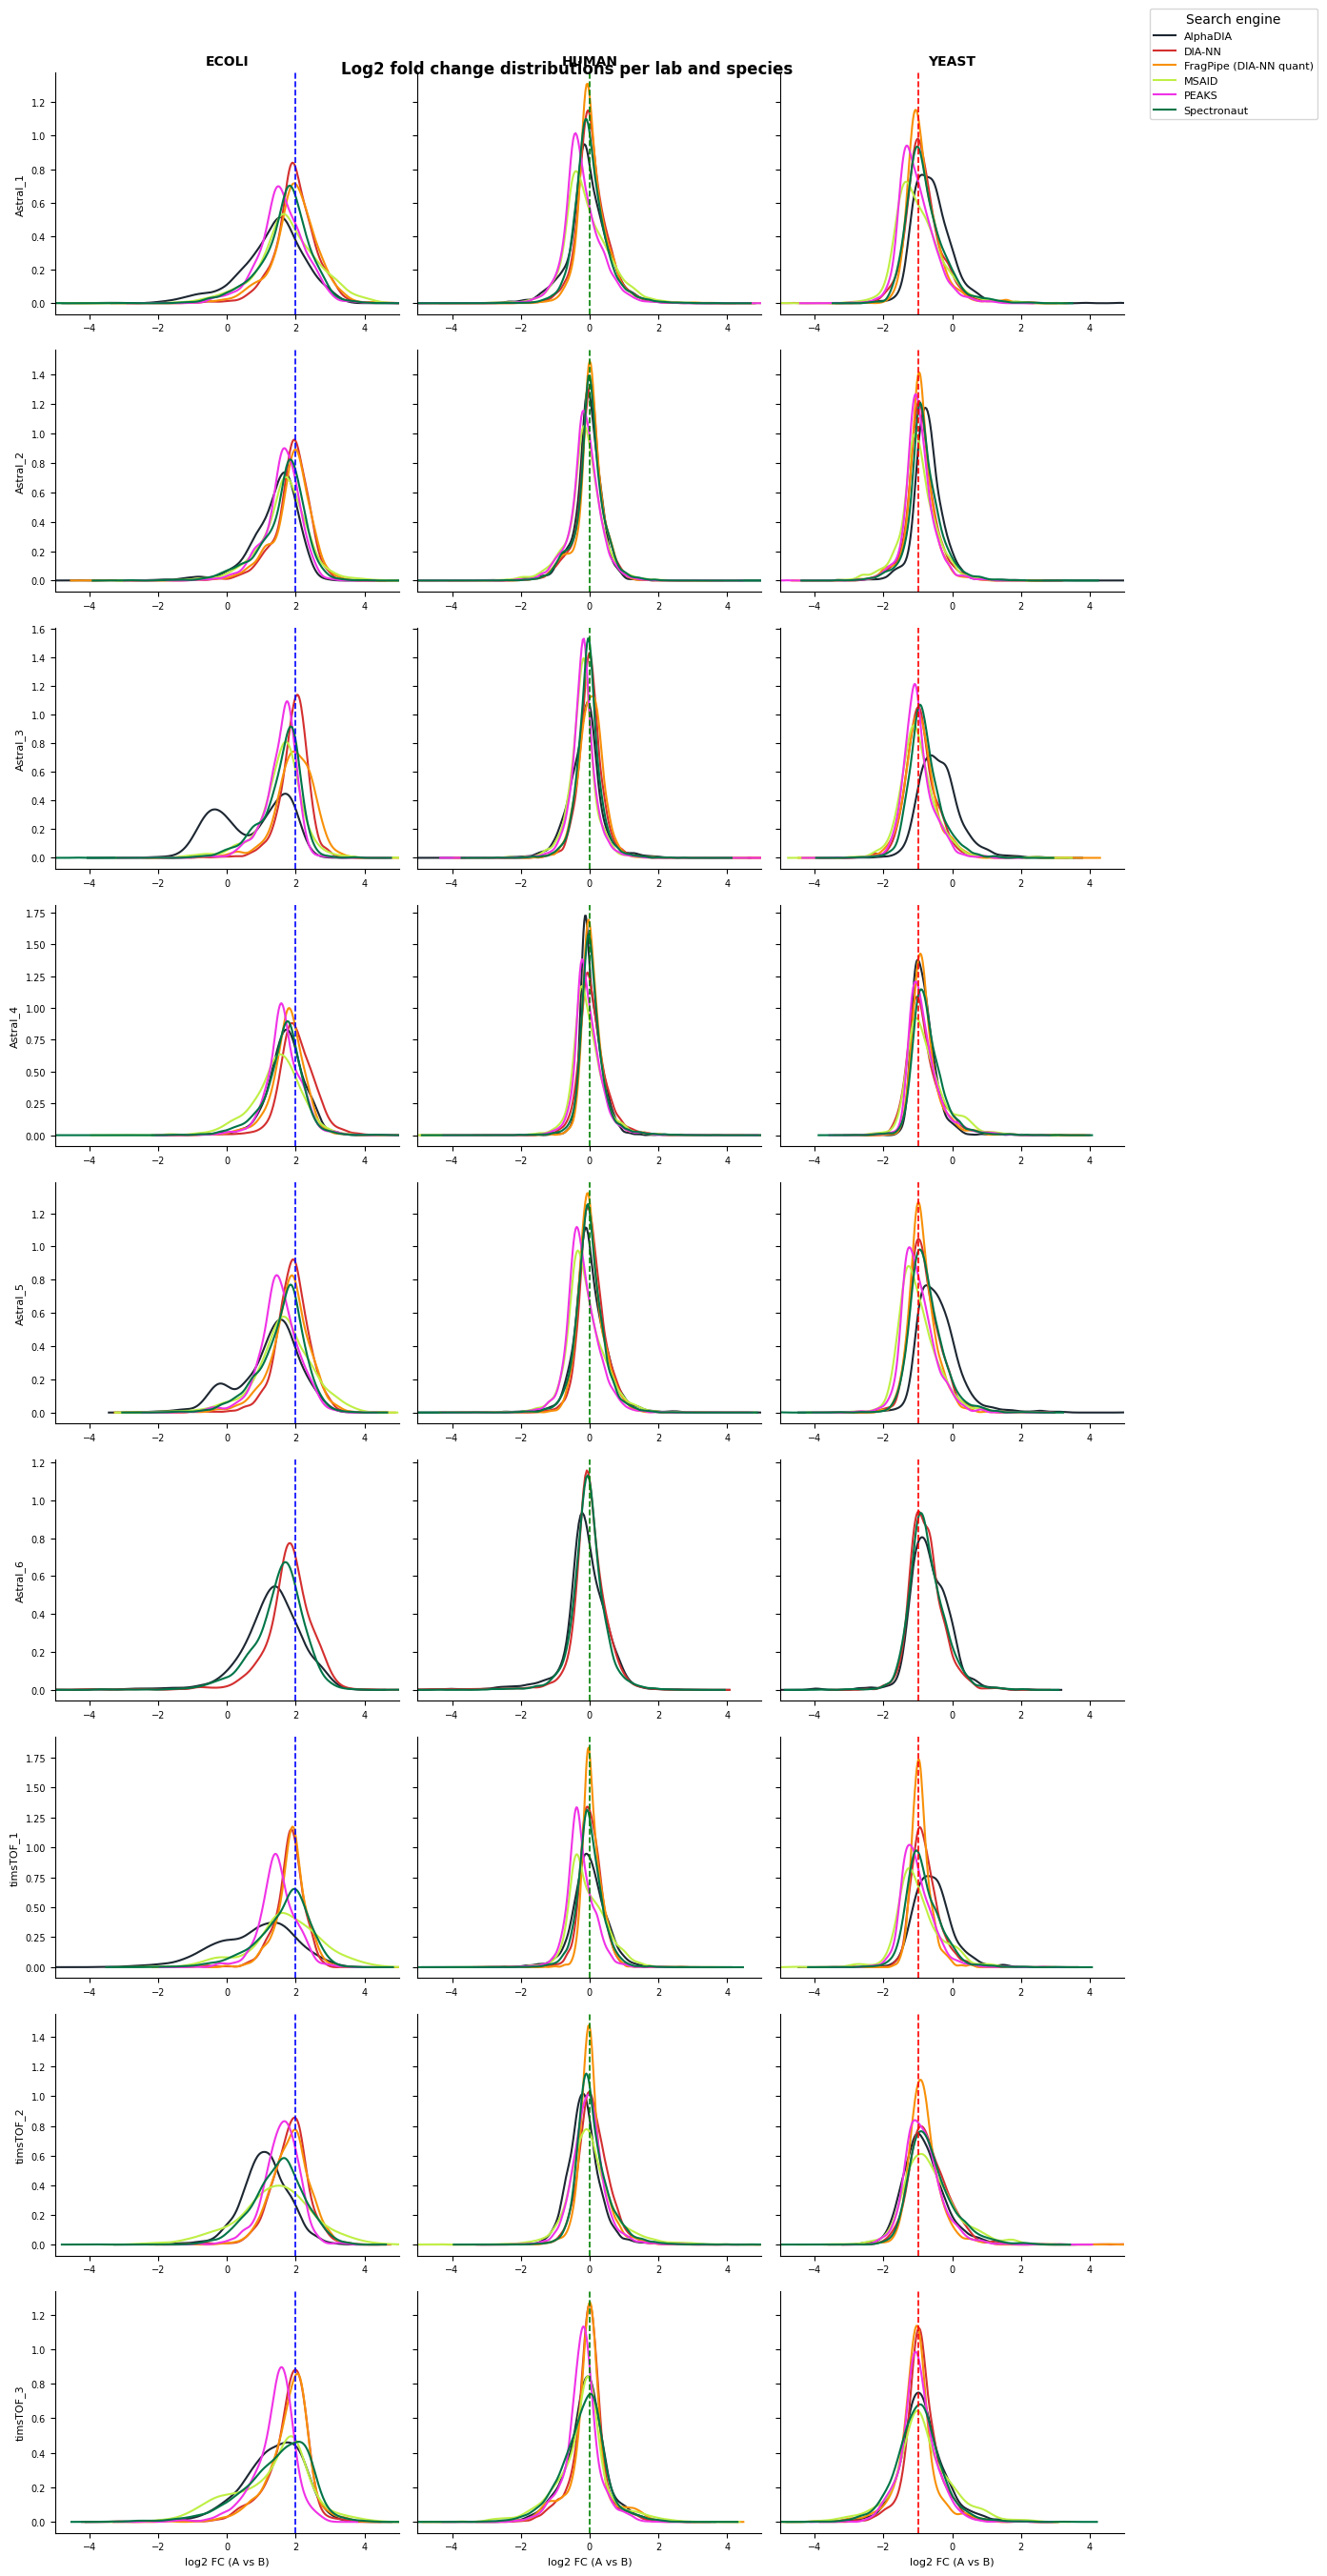

In [38]:
plot_species_distributions(
    intermediates    = selected_intermediates,
    species_config   = species_config,
    color_map        = SOFTWARE_COLORS,
    normalize_kde    = True,
    xlim_per_species = {'HUMAN': [-5, 5], 'YEAST': [-5, 5], 'ECOLI': [-5, 5]},
    save_dir         = os.path.join(FIGURE_PATH, 'Distribution'),
    filename         = 'species_distributions.png',
    show             = True,
)

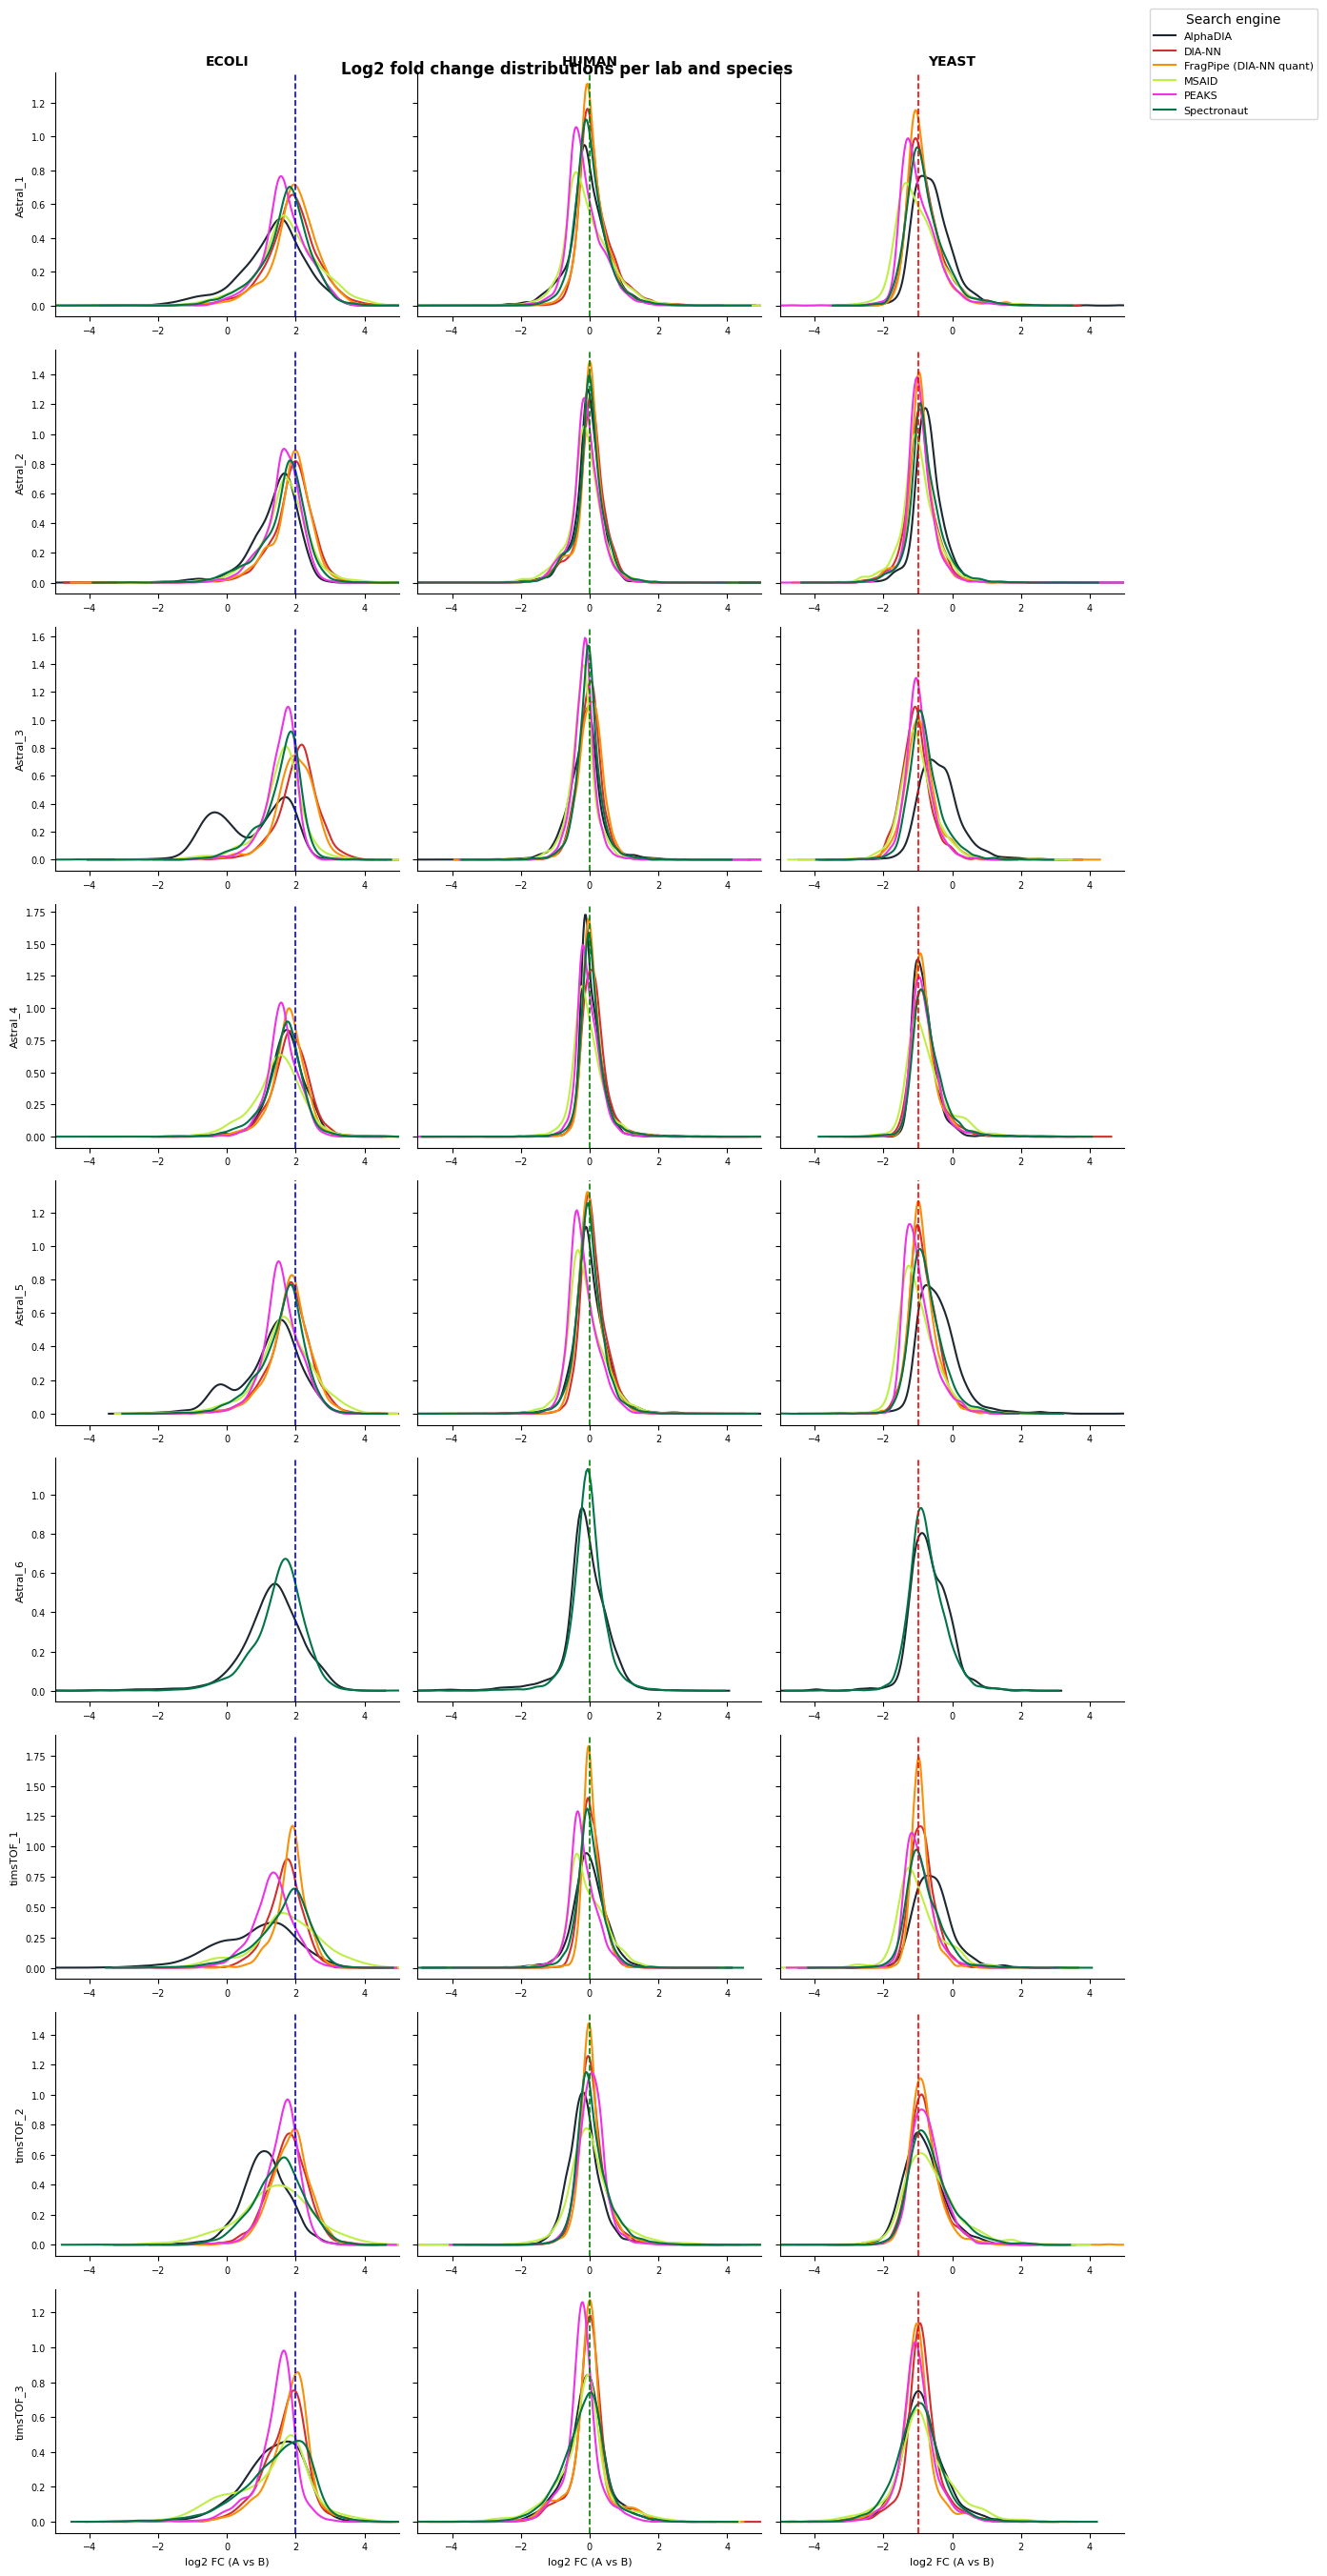

In [39]:
plot_species_distributions(
    intermediates    = selected_intermediates_mbr,
    species_config   = species_config,
    color_map        = SOFTWARE_COLORS,
    normalize_kde    = True,
    xlim_per_species = {'HUMAN': [-5, 5], 'YEAST': [-5, 5], 'ECOLI': [-5, 5]},
    save_dir         = os.path.join(FIGURE_PATH, 'Distribution'),
    filename         = 'species_distributions_mbr.png',
    show             = True,
)

## Boxplots and the rest

Processing timsTOF_3...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


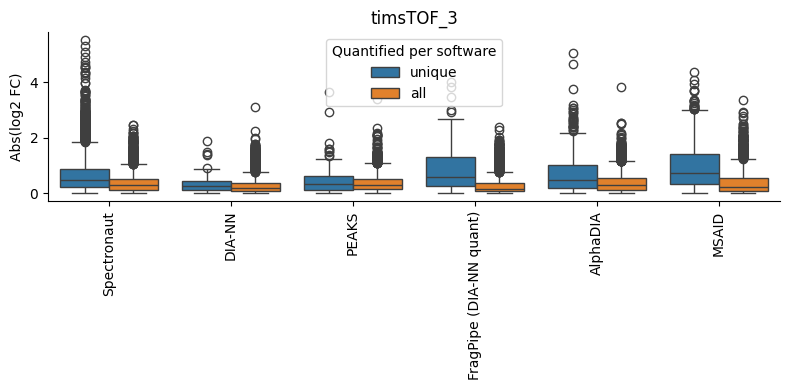

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

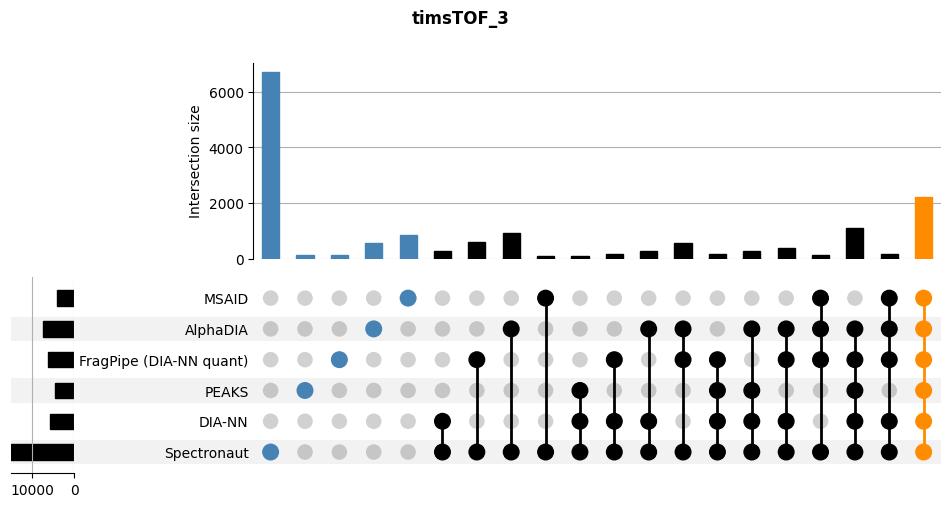

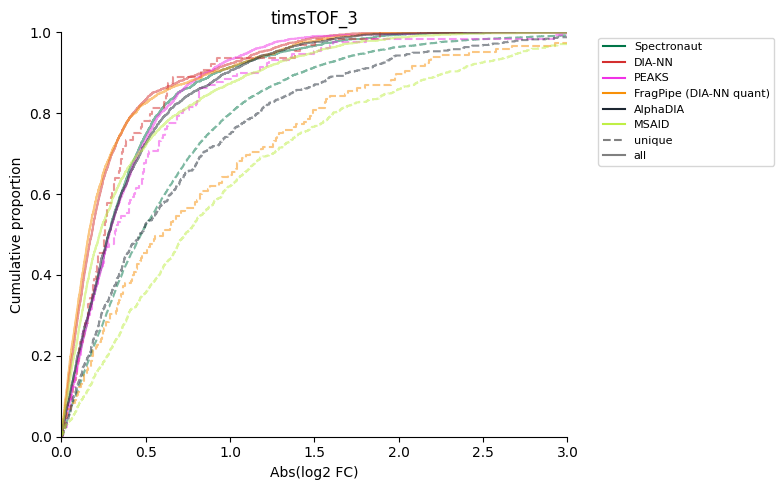

Processing timsTOF_2...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


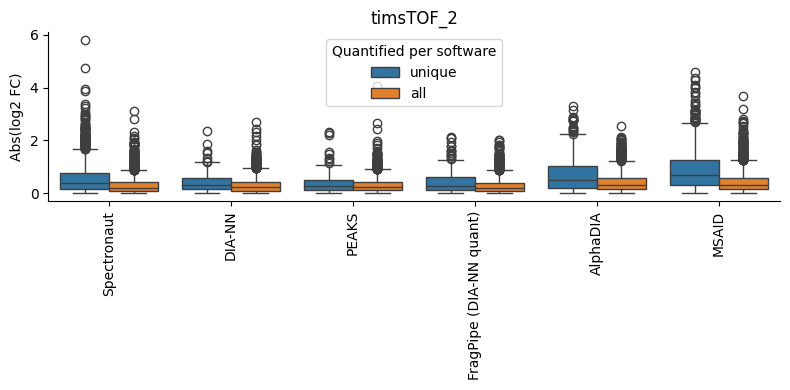

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

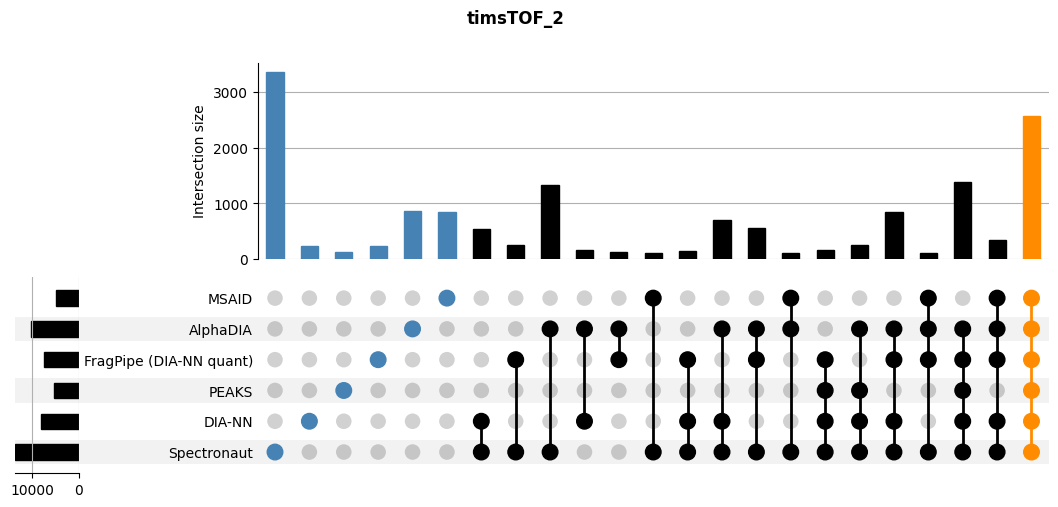

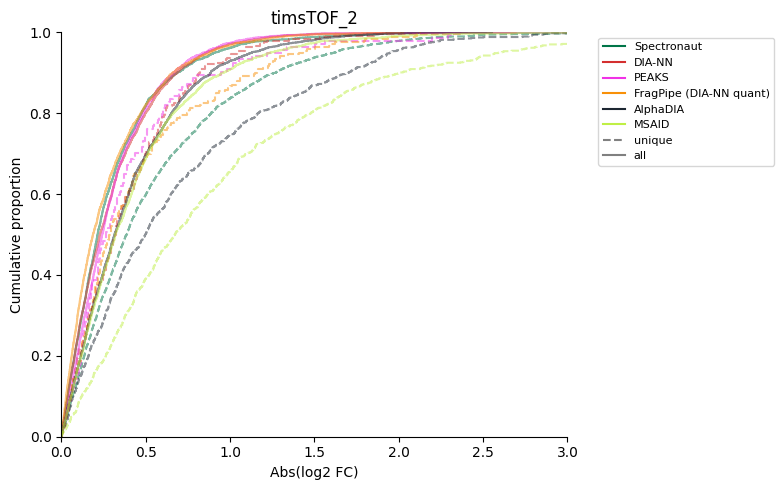

Processing Astral_3...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


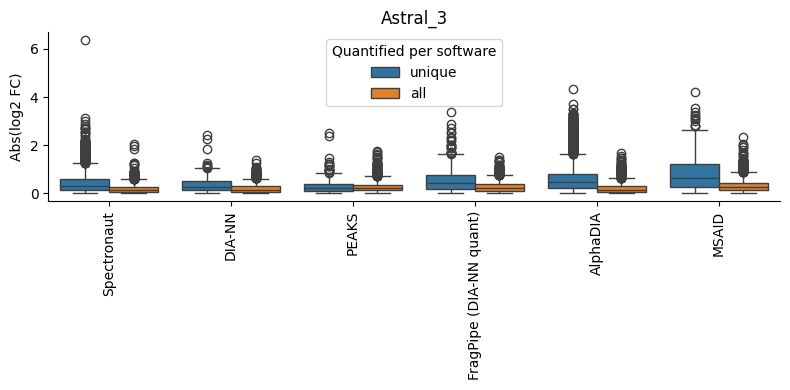

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

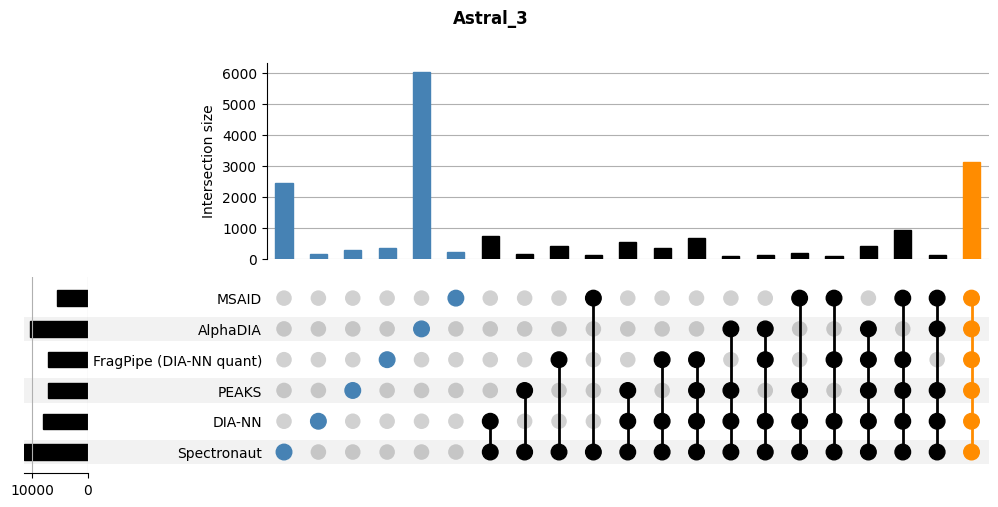

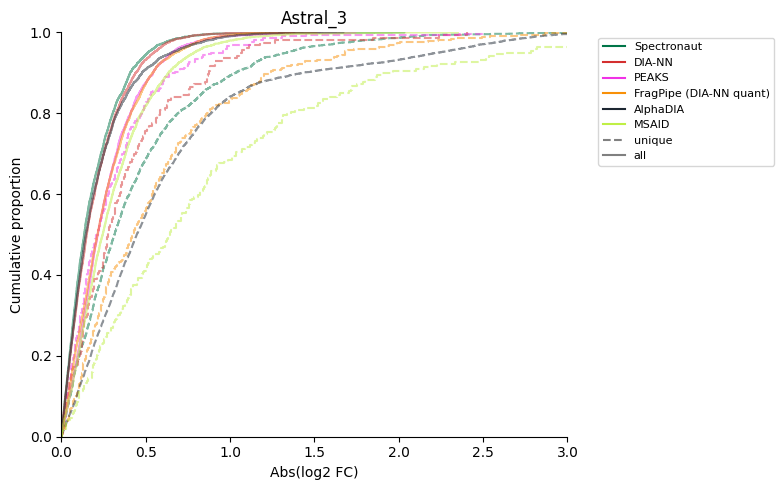

Processing Astral_2...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


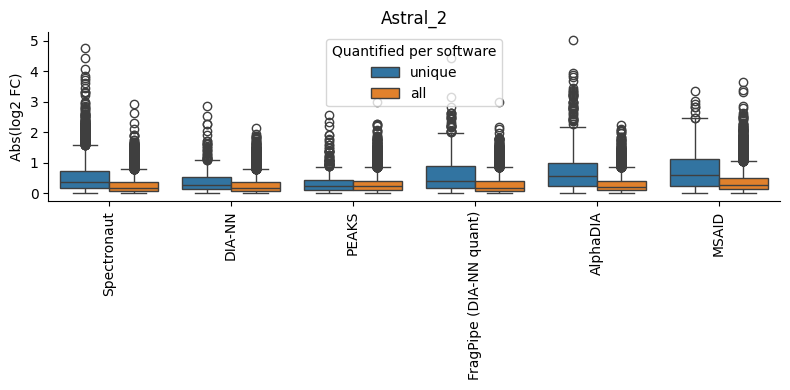

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

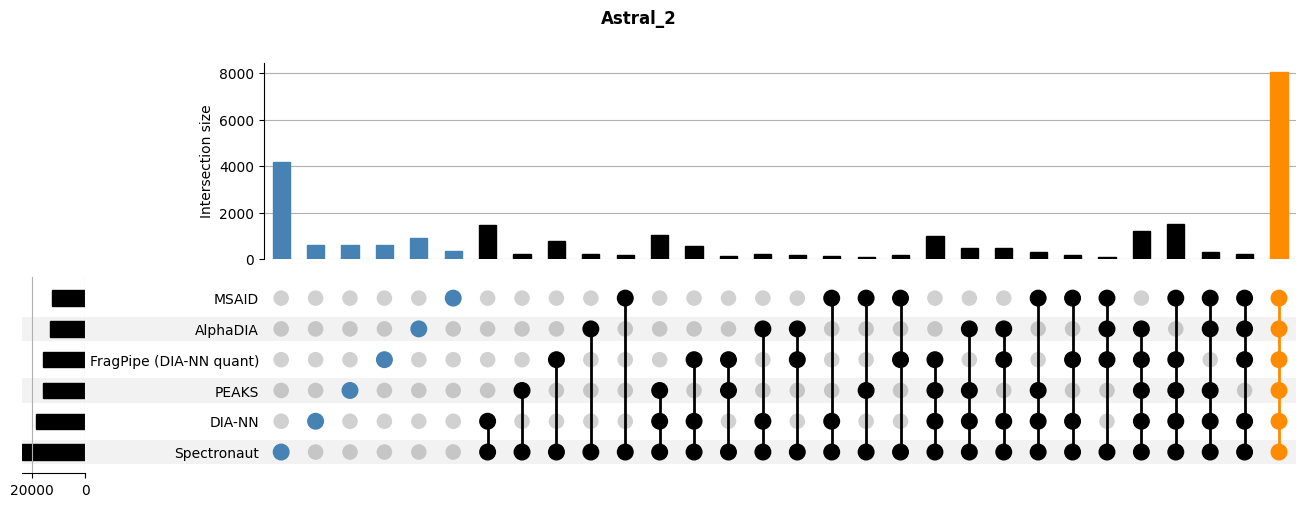

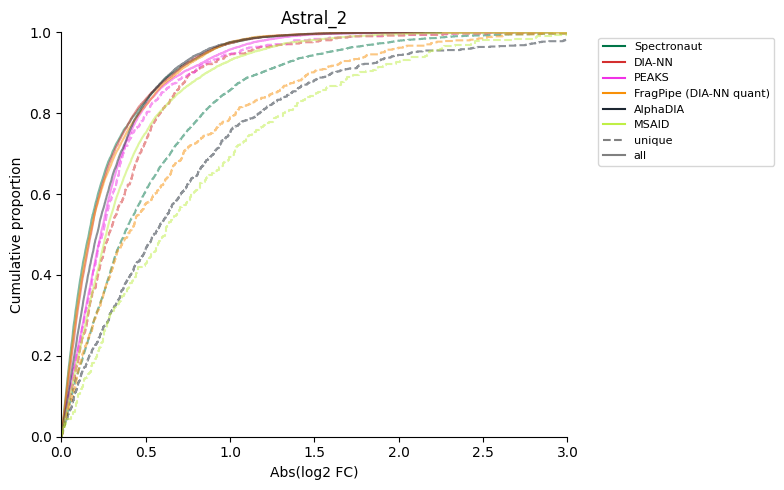

Processing Astral_6...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


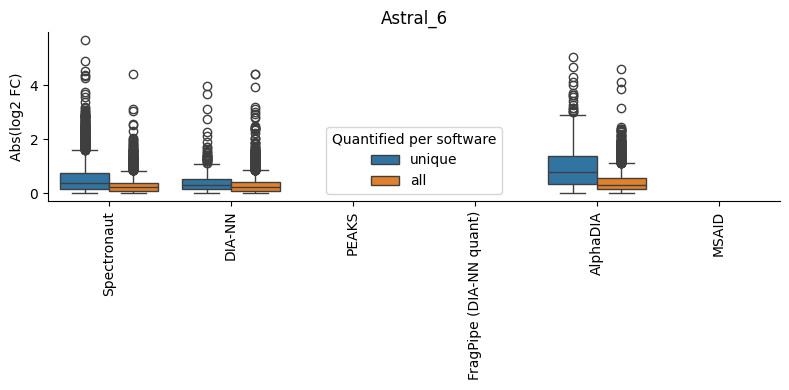

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

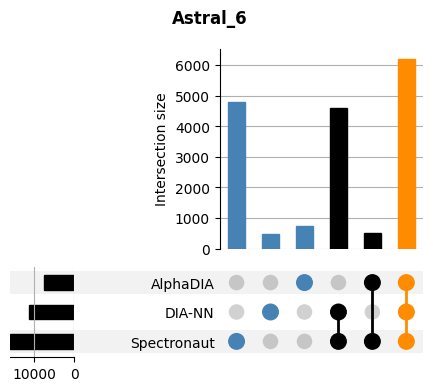

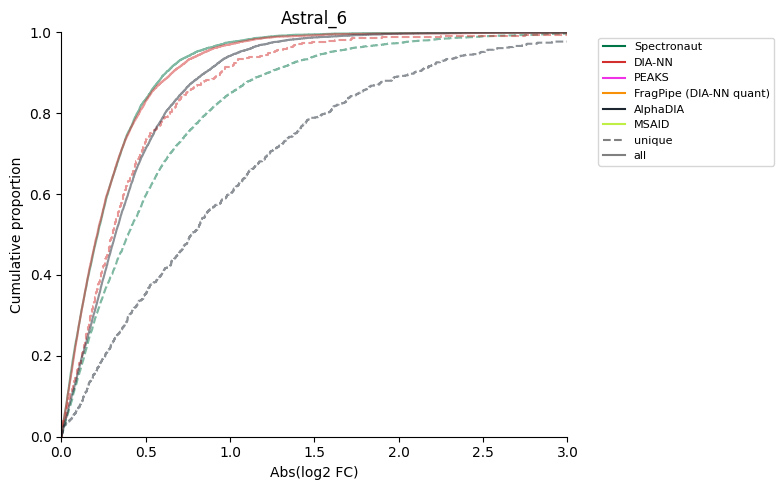

Processing Astral_1...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


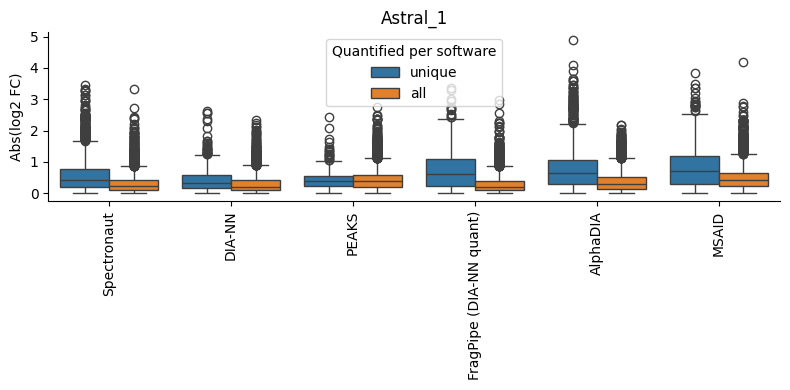

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

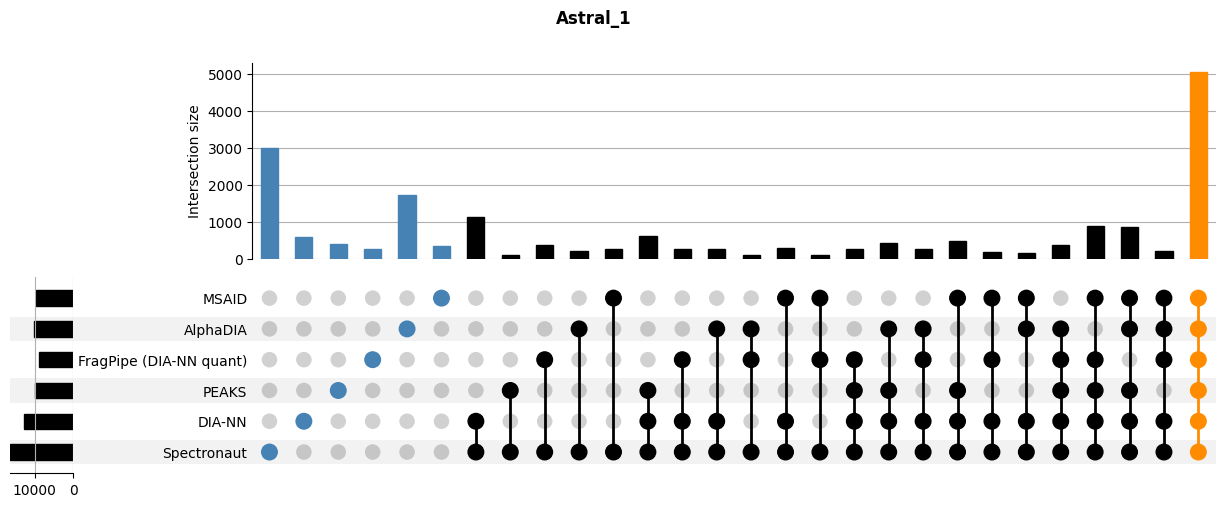

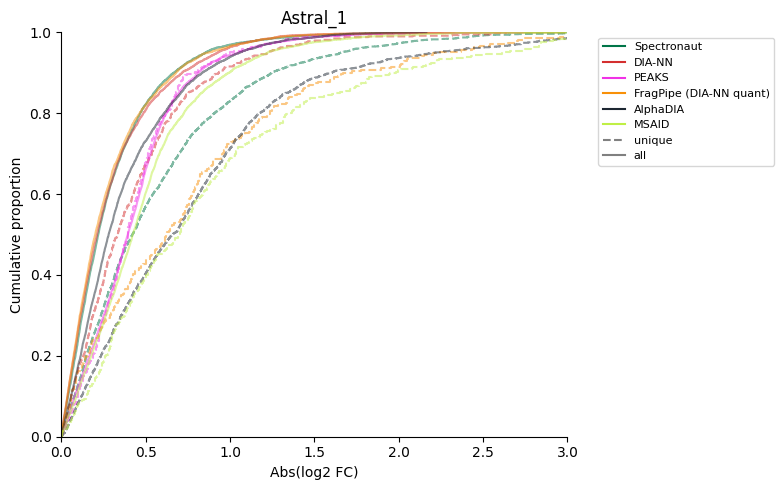

Processing Astral_5...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


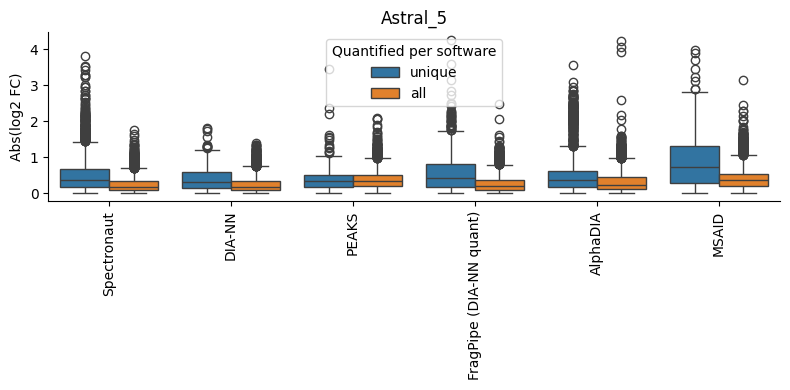

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

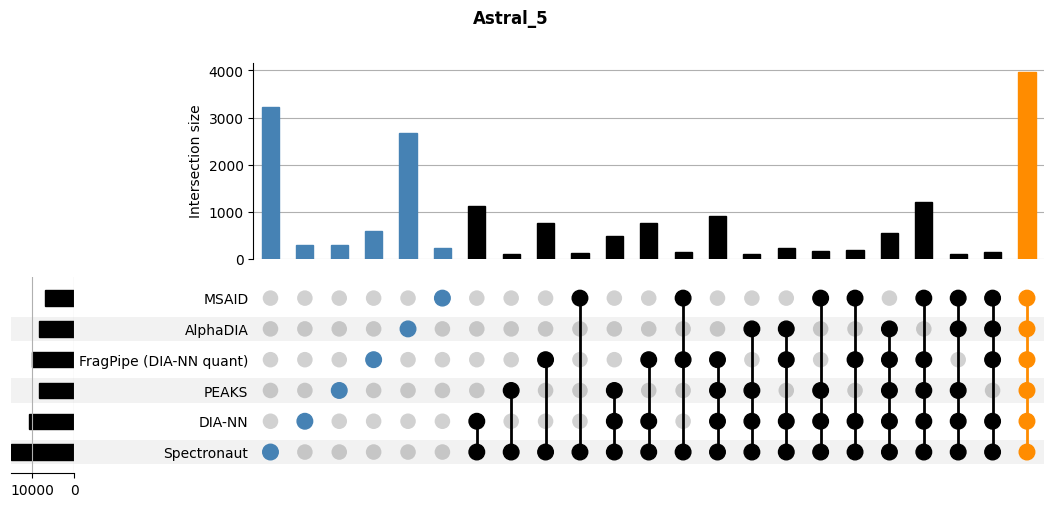

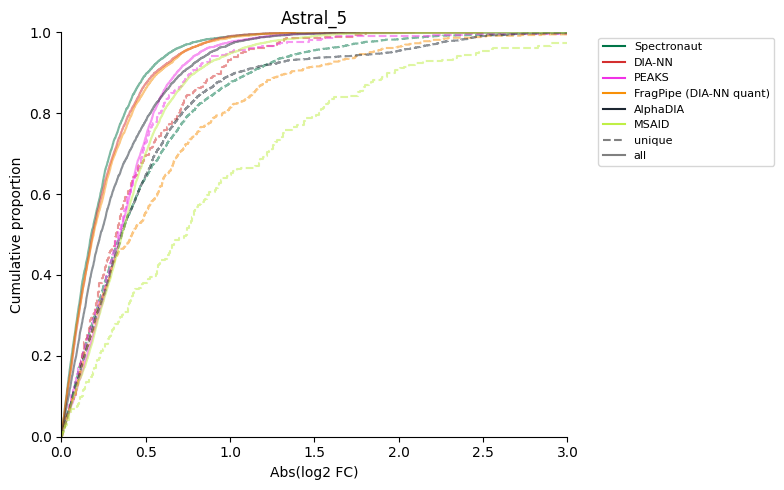

Processing Astral_4...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


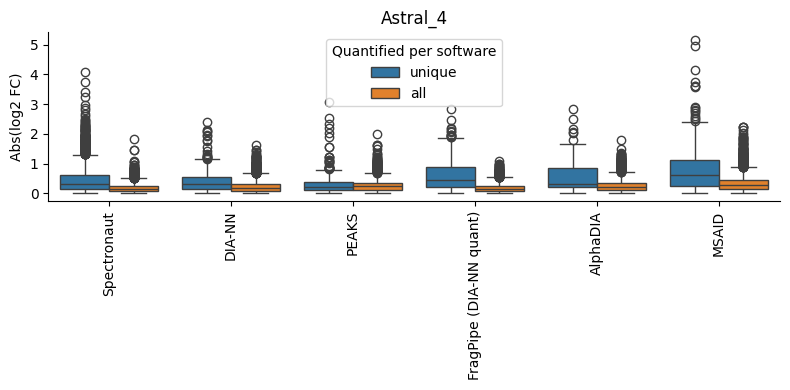

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

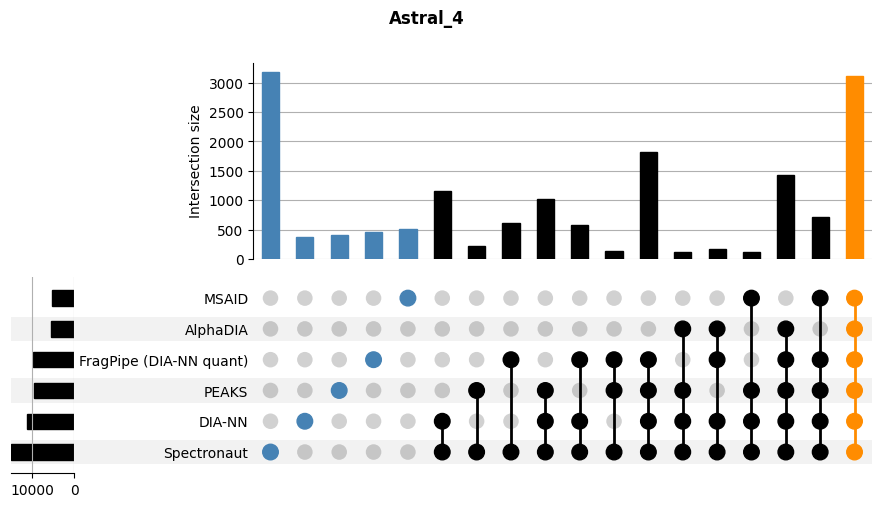

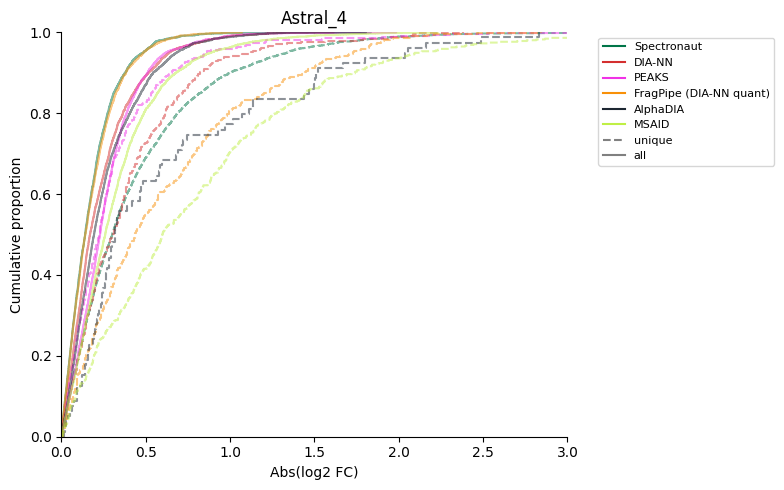

Processing timsTOF_1...


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


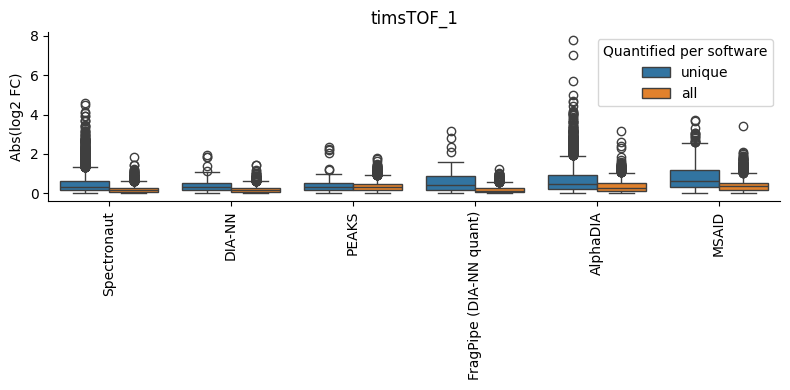

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting 

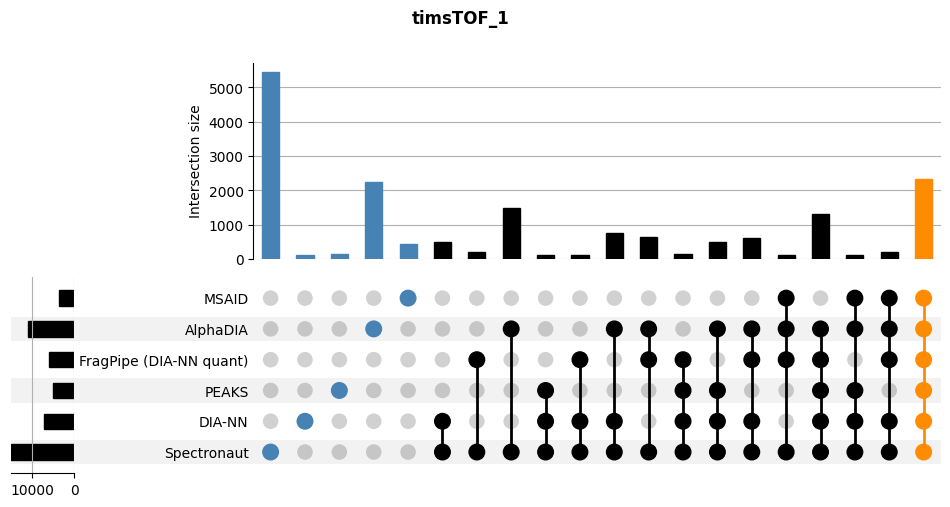

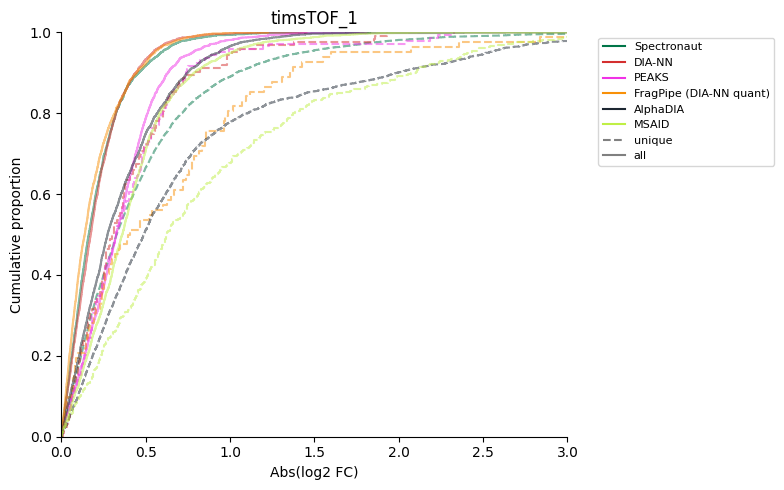

In [41]:
import upsetplot

# ── Constants ─────────────────────────────────────────────────────────────────
_KEEP_COLS = ['log2_A_vs_B', 'nr_observed', 'species',
              'precursor ion', 'lab', 'search_engine', 'AbsQuantError']

sample_type_A =  ['HYEA_QC_B13',
    'HYEA_QC_B14', 'HYEA_QC_B15',
    'HYEA_QC_B16', 'HYEA_QC_B17',
    'HYEA_QC_B18', 'HYEA_QC_B19',
    'HYEA_QC_B21', 'HYEA_QC_B22',
    'HYEA_QC_B23',]
sample_type_B = ['HYEB_QC_O10',
    'HYEB_QC_O11', 'HYEB_QC_O12',
    'HYEB_QC_O2', 'HYEB_QC_O3',
    'HYEB_QC_O4', 'HYEB_QC_O5',
    'HYEB_QC_O6', 'HYEB_QC_O7',
    'HYEB_QC_O8', 'HYEB_QC_O9']

save_dir = os.path.join(FIGURE_PATH, 'overlap_and_error')
# ── Data preparation ──────────────────────────────────────────────────────────
def intermediate_to_upsetplotdf(
    intermediate:  pd.DataFrame,
    min_prec:      int  = 5,
    per_condition: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Filter intermediate DataFrame and convert to UpSet plot format.

    Parameters
    ----------
    intermediate:
        Long-format DataFrame with precursor-level quantification.
    min_prec:
        Minimum number of observed precursors required per condition.
    per_condition:
        If ``True``, require ``min_prec`` in both condition A and B separately.
        If ``False``, require ``min_prec`` across all samples combined.

    Returns
    -------
    tuple of (UpSet DataFrame, filtered intermediate DataFrame)
    """
    sample_cols = intermediate.columns.tolist()

    if per_condition:
        mask = (
            intermediate[[c for c in sample_cols if c in sample_type_A]].notna().sum(axis=1) >= min_prec
        ) & (
            intermediate[[c for c in sample_cols if c in sample_type_B]].notna().sum(axis=1) >= min_prec
        )
    else:
        mask = (
            intermediate[[c for c in sample_cols if c in sample_type_A + sample_type_B]]
            .notna().sum(axis=1) >= min_prec
        )

    filtered = (
        intermediate
        .loc[mask, _KEEP_COLS]
        .reset_index(drop=True)
        .dropna()
    )

    ups = upsetplot.from_contents(
        filtered.groupby('search_engine')['precursor ion'].apply(set).to_dict()
    )
    return ups, filtered


def _build_selection_matrix(n_tools: int) -> list[tuple]:
    """Build selection index for unique-per-tool and all-tools subsets."""
    matrix = [[False] * n_tools for _ in range(n_tools)]
    for i in range(n_tools):
        matrix[i][i] = True
    matrix.append([True] * n_tools)
    return [tuple(row) for row in matrix]


def get_boxplot_data(
    ups:          pd.DataFrame,
    intermediate: pd.DataFrame,
    column:       str = 'AbsQuantError',
) -> pd.DataFrame:
    """
    Extract per-tool boxplot data for unique and all-tool precursor subsets.

    Parameters
    ----------
    ups:
        UpSet DataFrame from ``intermediate_to_upsetplotdf``.
    intermediate:
        Filtered intermediate DataFrame.
    column:
        Column to extract values from.

    Returns
    -------
    Long-format DataFrame with columns ``values``, ``tool``, ``subset``.
    """
    tools      = ups.index.names
    prec_map   = ups.reset_index().groupby(tools)['id'].apply(set)
    selection  = _build_selection_matrix(len(tools))

    rows = []
    for i, tool in enumerate(tools):
        for subset_label, idx in [('unique', selection[i]), ('all', selection[-1])]:
            precursors = prec_map[idx]
            values     = intermediate.loc[
                (intermediate['search_engine'] == tool) &
                (intermediate['precursor ion'].isin(precursors)),
                column
            ].tolist()
            rows.append({'values': values, 'tool': tool, 'subset': subset_label})

    return (
        pd.concat([pd.DataFrame(r) for r in rows], ignore_index=True)
        .rename(columns={'values': column, 'subset': 'Quantified per software'})
    )


# ── Plotting ──────────────────────────────────────────────────────────────────
def plot_boxplot(
    boxplot_data:   pd.DataFrame,
    lab_name:       str,
    ordering_tools: list[str],
    save_dir:       str | None = None,
    show:           bool       = True,
) -> None:
    """Boxplot of absolute quantification error per tool."""
    fig, ax = plt.subplots(figsize=(8, 4))

    sns.boxplot(
        data      = boxplot_data,
        x         = 'tool',
        y         = 'AbsQuantError',
        hue       = 'Quantified per software',
        order     = ordering_tools,
        ax        = ax,
    )
    ax.set(xlabel='', ylabel='Abs(log2 FC)', title=lab_name)
    ax.tick_params(axis='x', rotation=90)
    ax.spines[['top', 'right']].set_visible(False)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, f'{lab_name}_boxplot.png'))
    plt.show() if show else plt.close(fig)


def plot_upsetplot(
    ups:      pd.DataFrame,
    lab_name: str,
    save_dir: str | None = None,
    show:     bool       = True,
) -> None:
    """UpSet plot of precursor overlap across tools."""
    fig = plt.figure(figsize=(12, 6))
    fig.suptitle(lab_name, fontweight='bold')

    upset = upsetplot.UpSet(ups, sort_categories_by='input', min_subset_size=100)
    for subset in ups.index:
        degree = sum(subset)
        color  = 'steelblue' if degree == 1 else 'darkorange' if degree == len(ups.index.names) else 'black'
        upset.style_subsets(
            present = [name for name, val in zip(ups.index.names, subset) if val],
            absent  = [name for name, val in zip(ups.index.names, subset) if not val],
            facecolor = color,
        )
    upset.plot(fig=fig)

    if save_dir:
        _save(fig, os.path.join(save_dir, f'{lab_name}_upsetplot.png'))
    plt.show() if show else plt.close(fig)


def plot_ecdf(
    boxplot_data:   pd.DataFrame,
    lab_name:       str,
    ordering_tools: list[str],
    color_map:      dict,
    xlim:           tuple      = (0, 3),
    save_dir:       str | None = None,
    show:           bool       = True,
) -> None:
    """ECDF of absolute quantification error per tool and subset."""
    fig, ax = plt.subplots(figsize=(8, 5))

    linestyles = {'unique': '--', 'all': '-'}
    for tool in ordering_tools:
        color = color_map.get(tool, 'black')
        for subset, ls in linestyles.items():
            sub = boxplot_data[
                (boxplot_data['tool'] == tool) &
                (boxplot_data['Quantified per software'] == subset)
            ]
            sns.ecdfplot(sub, x='AbsQuantError', ax=ax,
                         color=color, linestyle=ls, linewidth=1.5, alpha=0.5)

    tool_handles  = [mlines.Line2D([], [], color=color_map.get(t, 'black'), label=t)
                     for t in ordering_tools]
    style_handles = [mlines.Line2D([], [], color='grey', linestyle=ls, label=qt)
                     for qt, ls in linestyles.items()]

    ax.legend(handles        = tool_handles + style_handles,
              bbox_to_anchor = (1.05, 1),
              loc            = 'upper left',
              fontsize       = 8)
    ax.set(xlabel='Abs(log2 FC)', ylabel='Cumulative proportion',
           title=lab_name, xlim=xlim)
    ax.spines[['top', 'right']].set_visible(False)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, f'{lab_name}_ecdf.png'))
    plt.show() if show else plt.close(fig)


# ── Main loop ─────────────────────────────────────────────────────────────────
ordering_tools = [
    'Spectronaut',
    'DIA-NN',
    'PEAKS',
    'FragPipe (DIA-NN quant)',
    'AlphaDIA',
    'MSAID',
]

slices = {}

for lab_name in selected_intermediates['lab'].unique():
    print(f"Processing {lab_name}...")

    df = selected_intermediates[selected_intermediates['lab'] == lab_name].copy()
    df['AbsQuantError'] = df['epsilon'].abs()

    ups, intermediate_filter = intermediate_to_upsetplotdf(df, min_prec=5, per_condition=False)
    new_index = [t for t in ordering_tools if t in ups.index.names]
    ups       = ups.reset_index().set_index(new_index)

    boxplot_data = get_boxplot_data(ups=ups, intermediate=intermediate_filter, column='AbsQuantError')

    plot_boxplot( boxplot_data, lab_name, ordering_tools, save_dir=save_dir, show=True)
    plot_upsetplot(ups,         lab_name,                 save_dir=save_dir, show=True)
    plot_ecdf(    boxplot_data, lab_name, ordering_tools, color_map=SOFTWARE_COLORS,
                  save_dir=save_dir, show=True)

    slices[lab_name] = {'ups': ups, 'intermediate': intermediate_filter}